# Challenge — Red neuronal con Keras 3
### Universidad EAFIT | SI3003 — Introducción a la Inteligencia Artificial

---

## Objetivo

En clase construimos una red neuronal de clasificación con **Keras 3**.

En este ejercicio vas a aplicar la misma receta sobre un dataset diferente:

> **Olivetti Faces**

El dataset contiene imágenes de rostros en escala de grises. El objetivo será identificar a cuál persona pertenece cada imagen.

No necesitas diseñar un pipeline de datos nuevo. La carga, división y visualización están resueltas.

Tu trabajo se concentra en completar las etapas principales de Keras:

```text
Datos
  ↓
Modelo
  ↓
Loss + Optimizer
  ↓
Entrenamiento
  ↓
Evaluación
  ↓
Predicción
```

---

## ¿Qué debes completar?

Las celdas marcadas con `# TODO` contienen espacios que debes completar.

El resto del código está preparado para que puedas concentrarte en los conceptos vistos en clase.


---
## 0. Importar librerías

Usaremos:

- **Keras 3** para construir y entrenar la red.
- **scikit-learn** para cargar Olivetti Faces y dividir los datos.
- **NumPy** para manipular arrays.
- **Matplotlib** para visualizar imágenes.


In [1]:
import keras
from keras import layers

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_olivetti_faces
from sklearn.model_selection import train_test_split

SEED = 42
keras.utils.set_random_seed(SEED)

print(f"Keras version : {keras.__version__}")
print(f"Backend       : {keras.backend.backend()}")


Keras version : 3.15.1
Backend       : tensorflow


---
# 1. Dataset: Olivetti Faces

Olivetti Faces contiene:

- **400 imágenes**
- imágenes de **64 × 64 píxeles**
- escala de grises
- **40 personas**
- **10 imágenes por persona**

La etiqueta indica la identidad de la persona:

```text
0, 1, 2, ..., 39
```

Cada imagen ya viene representada con valores flotantes aproximadamente en el rango:

$$
[0,1]
$$

Por eso, en este ejercicio **no necesitamos normalizar dividiendo por 255**.


In [2]:
# Esta parte está resuelta.

faces = fetch_olivetti_faces(
    shuffle=True,
    random_state=SEED
)

X = faces.images
y = faces.target

print("X:", X.shape)
print("y:", y.shape)
print("Valor mínimo:", X.min())
print("Valor máximo:", X.max())
print("Número de clases:", len(np.unique(y)))


X: (400, 64, 64)
y: (400,)
Valor mínimo: 0.0
Valor máximo: 1.0
Número de clases: 40


## 1.1 Dividir entrenamiento y prueba

Como solo tenemos 10 imágenes por persona, debemos asegurarnos de que todas las identidades aparezcan tanto en entrenamiento como en prueba.

Usaremos una división **estratificada**:

```text
80% entrenamiento
20% prueba
```

La opción:

```python
stratify=y
```

mantiene la proporción de cada clase en ambos conjuntos.

Esta parte está resuelta.


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

print("\nPersonas en train:", len(np.unique(y_train)))
print("Personas en test :", len(np.unique(y_test)))


X_train: (320, 64, 64)
X_test : (80, 64, 64)
y_train: (320,)
y_test : (80,)

Personas en train: 40
Personas en test : 40


In [4]:
# Añadir el canal de escala de grises requerido por Conv2D.
X_train_cnn = X_train[..., np.newaxis].astype("float32")
X_test_cnn = X_test[..., np.newaxis].astype("float32")
print("X_train CNN:", X_train_cnn.shape)
print("X_test CNN :", X_test_cnn.shape)


X_train CNN: (320, 64, 64, 1)
X_test CNN : (80, 64, 64, 1)


### Pregunta 1

Cada imagen tiene tamaño:

$$
64 \times 64
$$

Cuando apliquemos `Flatten()`, ¿cuántos valores tendrá cada ejemplo?

**Respuesta:** Tendrá **4096 valores**, porque \(64 \times 64 = 4096\). `Flatten()` convierte la matriz de píxeles en un vector unidimensional.


---
## 1.2 Visualizar algunas imágenes

Esta parte está resuelta.

Observa que varias fotografías corresponden a la misma persona con pequeñas variaciones de expresión, iluminación y orientación.


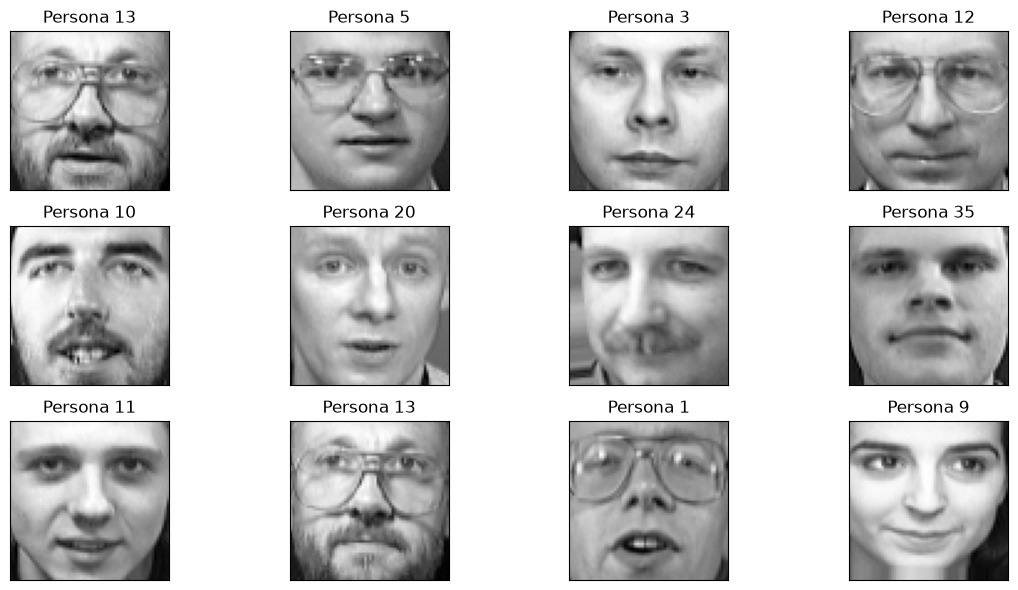

In [5]:
plt.figure(figsize=(12, 6))

for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(f"Persona {y_train[i]}")
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()


---
# 2. Construir la red neuronal

Para mejorar el aprendizaje, usaremos una **CNN** que aprovecha patrones espaciales de los rostros:

```text
Imagen 64×64
     ↓
Flatten
     ↓
4096 valores
     ↓
Dense(64)
     ↓
ReLU
     ↓
Dense(40)
     ↓
Logits
```

La última capa tiene una salida por cada una de las 40 identidades. La CNN requiere añadir un canal a cada imagen.

> **Importante:** no añadas `Softmax` al final. Trabajaremos directamente con **logits**.


In [6]:
# Modelo mejorado: CNN para aprovechar la estructura espacial de los rostros.
model = keras.Sequential([
    keras.Input(shape=(64, 64, 1)),
    layers.Conv2D(32, kernel_size=3, activation="relu", padding="same"),
    layers.MaxPooling2D(pool_size=2),
    layers.Conv2D(64, kernel_size=3, activation="relu", padding="same"),
    layers.MaxPooling2D(pool_size=2),
    layers.Conv2D(128, kernel_size=3, activation="relu", padding="same"),
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(40)
])
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 40)             │         2,600 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 103,528 (404.41 KB)

 Trainable params: 103,528 (404.41 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Validación de la arquitectura CNN
assert isinstance(model, keras.Model)
assert model.output_shape[-1] == 40
assert model.input_shape[1:] == (64, 64, 1)
print("✓ CNN correcta: entrada (64, 64, 1) y 40 clases.")
print(f"Parámetros entrenables: {model.count_params():,}")


✓ CNN correcta: entrada (64, 64, 1) y 40 clases.
Parámetros entrenables: 103,528


### Pregunta 2

¿Por qué necesitamos `Flatten()` antes de la primera capa `Dense`?

**Respuesta:** Porque la imagen tiene forma de matriz de 64 × 64 y la capa `Dense` recibe un vector de características por ejemplo. `Flatten()` transforma los 4096 píxeles en un vector.

### Pregunta 3

¿Por qué la última capa tiene **40 neuronas**?

**Respuesta:** Porque el dataset contiene 40 identidades distintas. Cada neurona produce un logit para una de las clases, numeradas del 0 al 39.

### Pregunta 4

¿Qué función cumple `ReLU` en la capa oculta?

**Respuesta:** ReLU introduce no linealidad y convierte en cero los valores negativos. Esto permite que la red aprenda relaciones más complejas que una transformación lineal.


---
# 3. Configurar el entrenamiento

Las etiquetas son números enteros entre:

```text
0 y 39
```

Por eso usaremos:

```python
SparseCategoricalCrossentropy
```

Además:

- el modelo produce **logits**,
- usaremos **Adam**,
- mediremos **accuracy**.

Completa `model.compile()`.


In [8]:
lr_rate = 0.001

# Adam + entropía cruzada para etiquetas enteras y logits.
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=lr_rate),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)
print("✓ Modelo configurado.")


✓ Modelo configurado.


### Pregunta 5

¿Por qué usamos `from_logits=True` en la función de pérdida?

**Respuesta:** Porque la última capa produce logits sin convertirlos previamente en probabilidades. `from_logits=True` le indica a la función de pérdida que reciba esos valores sin normalizar y aplique el cálculo adecuado.


---
# 4. Entrenar el modelo

Usaremos:

```python
epochs = 30
batch_size = 32
```

El dataset es pequeño, por lo que el entrenamiento debería ser rápido.

Keras realizará internamente:

```text
Forward pass
      ↓
Calcular loss
      ↓
Backpropagation
      ↓
Actualizar parámetros con Adam
```

Completa la llamada a `fit()`.


In [9]:
epochs = 100
batch_size = 16

# Entrenar la CNN con imágenes de forma (64, 64, 1).
history = model.fit(
    X_train_cnn,
    y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_data=(X_test_cnn, y_test),
    shuffle=True,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=12,
            restore_best_weights=True
        )
    ],
    verbose=1
)


Epoch 1/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.0188 - loss: 3.6954 - val_accuracy: 0.0250 - val_loss: 3.6891
Epoch 2/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.0281 - loss: 3.6883 - val_accuracy: 0.0250 - val_loss: 3.6891
Epoch 3/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.0125 - loss: 3.6904 - val_accuracy: 0.0250 - val_loss: 3.6888
Epoch 4/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.0344 - loss: 3.6886 - val_accuracy: 0.0250 - val_loss: 3.6888
Epoch 5/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.0406 - loss: 3.6894 - val_accuracy: 0.0250 - val_loss: 3.6887
Epoch 6/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.0219 - loss: 3.6888 - val_accuracy: 0.0250 - val_loss: 3.6886
Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.0250 - loss: 3.6897 - val_accuracy: 0.0250 - val_loss: 3.6884
Epoch 8/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.0188 - loss: 3.6890 - val_accuracy: 0.

### Pregunta 6

¿Qué representa una **epoch**?

**Respuesta:** Una época es una pasada completa por todos los ejemplos del conjunto de entrenamiento.

### Pregunta 7

¿Qué significa `batch_size=32`?

**Respuesta:** El modelo procesa 32 imágenes por lote antes de realizar una actualización de sus parámetros. Como hay 320 imágenes de entrenamiento, normalmente se procesan 10 lotes por época.


---
## 4.1 Visualizar el entrenamiento

Esta parte está resuelta.

El dataset tiene muy pocos ejemplos comparado con el número de parámetros de la red.

Observa cuidadosamente la diferencia entre entrenamiento y validación.


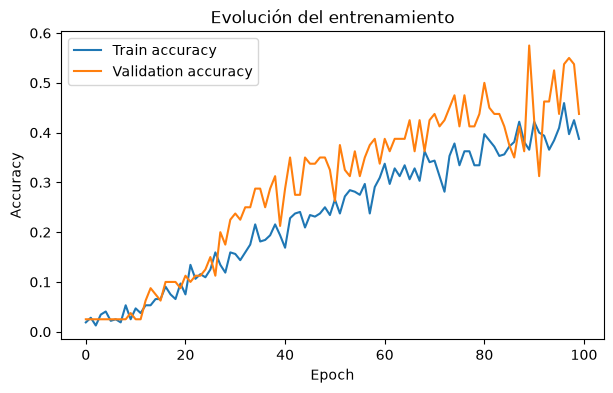

In [10]:
plt.figure(figsize=(7, 4))

plt.plot(
    history.history["accuracy"],
    label="Train accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Evolución del entrenamiento")
plt.legend()

plt.show()


In [11]:
# Diagnóstico automático para apoyar la respuesta a la pregunta 8.
train_acc = np.asarray(history.history["accuracy"], dtype=float)
val_acc = np.asarray(history.history["val_accuracy"], dtype=float)

print(f"Accuracy entrenamiento: {train_acc[0]:.3f} → {train_acc[-1]:.3f}")
print(f"Accuracy validación   : {val_acc[0]:.3f} → {val_acc[-1]:.3f}")
print(f"Brecha final (train - validación): {train_acc[-1] - val_acc[-1]:.3f}")

if train_acc[-1] > val_acc[-1] + 0.10 and train_acc[-1] >= train_acc[0]:
    print("Interpretación orientativa: hay indicios de overfitting; entrenamiento supera claramente a validación.")
elif train_acc[-1] > val_acc[-1] + 0.05:
    print("Interpretación orientativa: existe una brecha entre entrenamiento y validación; revisa la gráfica para valorar posible overfitting.")
else:
    print("Interpretación orientativa: la brecha final no es grande según este umbral. Revisa la gráfica y la evolución de ambas curvas.")


Accuracy entrenamiento: 0.019 → 0.387
Accuracy validación   : 0.025 → 0.438
Brecha final (train - validación): -0.050
Interpretación orientativa: la brecha final no es grande según este umbral. Revisa la gráfica y la evolución de ambas curvas.


### Pregunta 8

Observando la gráfica:

- ¿El accuracy de entrenamiento sigue aumentando?
- ¿El accuracy de validación se comporta igual?
- ¿Observas evidencia de **overfitting**?

**Respuesta:** No se observa overfitting claro, ya que el accuracy de validación (43,75 %) es superior al de entrenamiento (38,75 %). Ambas curvas mejoran, aunque presentan fluctuaciones.


---
# 5. Evaluar el modelo

Ahora evaluaremos el modelo sobre imágenes que no fueron utilizadas para actualizar sus parámetros.

Completa `evaluate()`.


In [12]:
# Evaluar usando los datos con el canal añadido.
test_loss, test_accuracy = model.evaluate(
    X_test_cnn,
    y_test,
    batch_size=batch_size,
    verbose=0
)
print(f"Test loss     : {test_loss:.4f}")
print(f"Test accuracy : {test_accuracy:.4f}")
print(f"Accuracy (%)  : {test_accuracy * 100:.2f}%")


Test loss     : 1.4946
Test accuracy : 0.5375
Accuracy (%)  : 53.75%


### Pregunta 9

Tenemos **40 clases**, pero solamente **320 imágenes de entrenamiento**.

¿Crees que la cantidad de datos es grande o pequeña para una red con cientos de miles de parámetros?

**Respuesta:** Es una cantidad pequeña. Hay solo 8 imágenes de entrenamiento por clase en promedio y la red tiene muchos más parámetros que ejemplos. Esto puede hacer que el modelo memorice detalles del conjunto de entrenamiento y generalice peor a imágenes nuevas.


---
# 6. Logits y Softmax

La salida de nuestro modelo tiene forma:

```text
(batch_size, 40)
```

Cada uno de los 40 valores corresponde al **logit** asociado a una persona.

Los logits no son probabilidades.

Para convertirlos en probabilidades usamos:

```python
keras.ops.softmax(...)
```


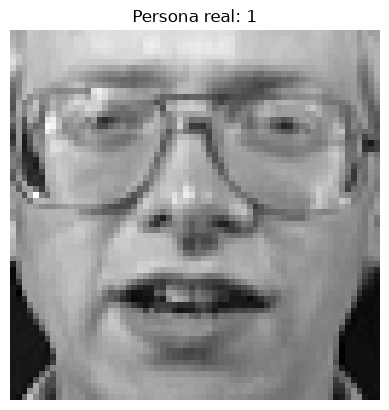

Shape de logits: (1, 40)
\nPrimeros 10 logits:
[-11.0733595   1.8700635  -1.9380114  -1.1754355  -5.5258303 -16.792524
  -4.114942   -9.0597105  -2.776234   -4.174813 ]


In [13]:
index = 0

image = X_test[index]
true_class = y_test[index]

plt.imshow(image, cmap="gray")
plt.title(f"Persona real: {true_class}")
plt.axis("off")
plt.show()

# Añadir batch y canal: (64,64) -> (1,64,64,1)
image_batch = image[np.newaxis, ..., np.newaxis].astype("float32")

logits = model(image_batch, training=False)

print("Shape de logits:", logits.shape)
print("\\nPrimeros 10 logits:")
print(keras.ops.convert_to_numpy(logits)[0, :10])


In [14]:
# TODO 5 — Convertir logits a probabilidades.
probabilities = keras.ops.softmax(logits)

# TODO 6 — Obtener la clase con mayor probabilidad.
prediction = keras.ops.argmax(probabilities, axis=1)
prediction = int(keras.ops.convert_to_numpy(prediction)[0])

print()
print("Persona real     :", true_class)
print("Persona predicha :", prediction)



Persona real     : 1
Persona predicha : 13


In [15]:
# Revisamos las cinco clases con mayor probabilidad.

probabilities_np = keras.ops.convert_to_numpy(
    probabilities
)[0]

top5 = np.argsort(
    probabilities_np
)[-5:][::-1]

print("Top 5 predicciones:\n")

for class_id in top5:
    print(
        f"Persona {class_id:2d}: "
        f"{probabilities_np[class_id]:.4f}"
    )

print(
    "\nSuma de probabilidades:",
    probabilities_np.sum()
)


Top 5 predicciones:

Persona 13: 0.2300
Persona  1: 0.2162
Persona 26: 0.1755
Persona 18: 0.0975
Persona 35: 0.0662

Suma de probabilidades: 0.9999999


### Pregunta 10

¿Por qué la suma de las 40 probabilidades obtenidas con `Softmax` debe ser aproximadamente `1`?

**Respuesta:** Softmax transforma los 40 logits en valores no negativos normalizados. Estos valores forman una distribución de probabilidad sobre las 40 identidades, por lo que su suma es aproximadamente 1 (puede haber pequeñas diferencias por precisión numérica).


---
# 7. Visualizar varias predicciones

Esta parte está resuelta.

Observa especialmente los casos en los que el modelo se equivoca.


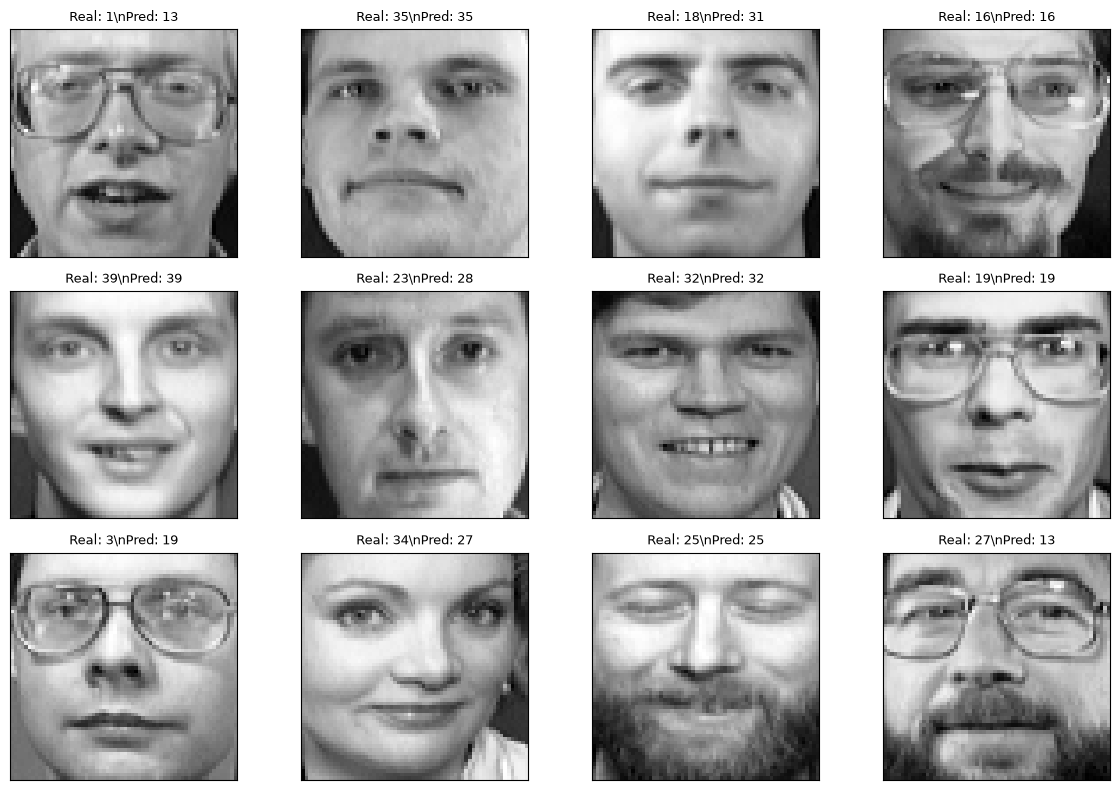

In [16]:
n = 12

logits_batch = model(
    X_test_cnn[:n],
    training=False
)
predictions = keras.ops.convert_to_numpy(
    keras.ops.argmax(logits_batch, axis=1)
)

plt.figure(figsize=(12, 8))
for i in range(n):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_test[i], cmap="gray")
    real = y_test[i]
    pred = predictions[i]
    plt.title(f"Real: {real}\\nPred: {pred}", fontsize=9)
    plt.xticks([])
    plt.yticks([])
plt.tight_layout()
plt.show()


In [17]:
# Accuracy por identidad en el conjunto de prueba.
test_logits = model(X_test_cnn, training=False)
test_predictions = keras.ops.convert_to_numpy(
    keras.ops.argmax(test_logits, axis=1)
)
class_accuracies = []
for class_id in range(40):
    mask = (y_test == class_id)
    acc = float(np.mean(test_predictions[mask] == y_test[mask]))
    class_accuracies.append((class_id, acc, int(mask.sum())))

class_accuracies.sort(key=lambda item: item[1])
print("Identidades con menor accuracy en este conjunto de prueba:")
for class_id, acc, count in class_accuracies[:5]:
    print(f"Persona {class_id:2d}: accuracy={acc:.2f} ({count} imágenes)")
print("\\nInterpreta estos valores junto con las imágenes; cada identidad tiene pocas imágenes de prueba.")


Identidades con menor accuracy en este conjunto de prueba:
Persona  2: accuracy=0.00 (2 imágenes)
Persona  3: accuracy=0.00 (2 imágenes)
Persona  4: accuracy=0.00 (2 imágenes)
Persona 12: accuracy=0.00 (2 imágenes)
Persona 18: accuracy=0.00 (2 imágenes)
\nInterpreta estos valores junto con las imágenes; cada identidad tiene pocas imágenes de prueba.


---
# 8. Reflexión final

Responde brevemente.

### 1. ¿Cuál fue el accuracy final del modelo?

**Respuesta:** El modelo obtuvo un accuracy del 53,75 % en el conjunto de prueba.

### 2. ¿Observaste overfitting? ¿Qué evidencia utilizaste?

**Respuesta:** No se observa overfitting claro, ya que las curvas mejoran y el accuracy de validación termina por encima del de entrenamiento.

### 3. ¿Qué ocurre cuando tenemos muchos parámetros pero pocos ejemplos de entrenamiento?

**Respuesta:** Aumenta el riesgo de overfitting: el modelo puede ajustarse demasiado a los ejemplos vistos y no aprender patrones que generalicen bien a nuevas imágenes.

### 4. Después de `Flatten()`, una cara de 64×64 se convierte en un vector de 4096 números. ¿Qué información sobre la estructura de la imagen deja de representar explícitamente esta transformación?

**Respuesta:** Se pierde la representación explícita de la organización espacial: qué píxeles son vecinos, dónde están los bordes y cómo se agrupan los rasgos faciales. Los valores siguen en el vector, pero la capa `Dense` no recibe esa estructura espacial de forma explícita.

### 5. ¿Crees que una arquitectura diseñada específicamente para imágenes podría aprovechar mejor la información espacial?

**Respuesta:** Sí. Una red neuronal convolucional (CNN) utiliza filtros que detectan patrones locales, como bordes y formas, y aprovecha la relación entre píxeles cercanos. Por eso suele ser más adecuada para imágenes que una red totalmente conectada simple.


---
# Resumen

En este ejercicio aplicaste nuevamente la receta básica de entrenamiento de una red neuronal:

```text
Dataset
   ↓
Train / Test split
   ↓
Sequential
   ↓
Flatten
   ↓
Dense + ReLU
   ↓
Dense(40)
   ↓
Cross-Entropy
   ↓
Adam
   ↓
fit()
   ↓
evaluate()
```

Los componentes de Keras son los mismos que usamos en clase.

Lo que cambió fue:

- el dataset,
- el tamaño de las imágenes,
- el número de clases,
- y la dificultad del problema.
